# Data Extraction

Cleans the raw credit risk dataset for downstream use.

**Contents:**
- `extract_data()` — drops rows with missing `person_emp_length` or `loan_int_rate`.
- NaN check — fetches the raw dataset, runs `extract_data`, asserts the result has zero NaNs, and charts NaN vs. non-NaN counts per field before and after extraction.

In [3]:
from pandas import DataFrame

def extract_data(dataset: DataFrame) -> DataFrame:
    return dataset.dropna(subset=["person_emp_length", "loan_int_rate"])

## NaN check

`extract_data` drops rows with missing `person_emp_length` or `loan_int_rate`, so the extracted dataset should contain **zero** NaNs in any field. The chart below compares NaN vs. non-NaN counts per field.

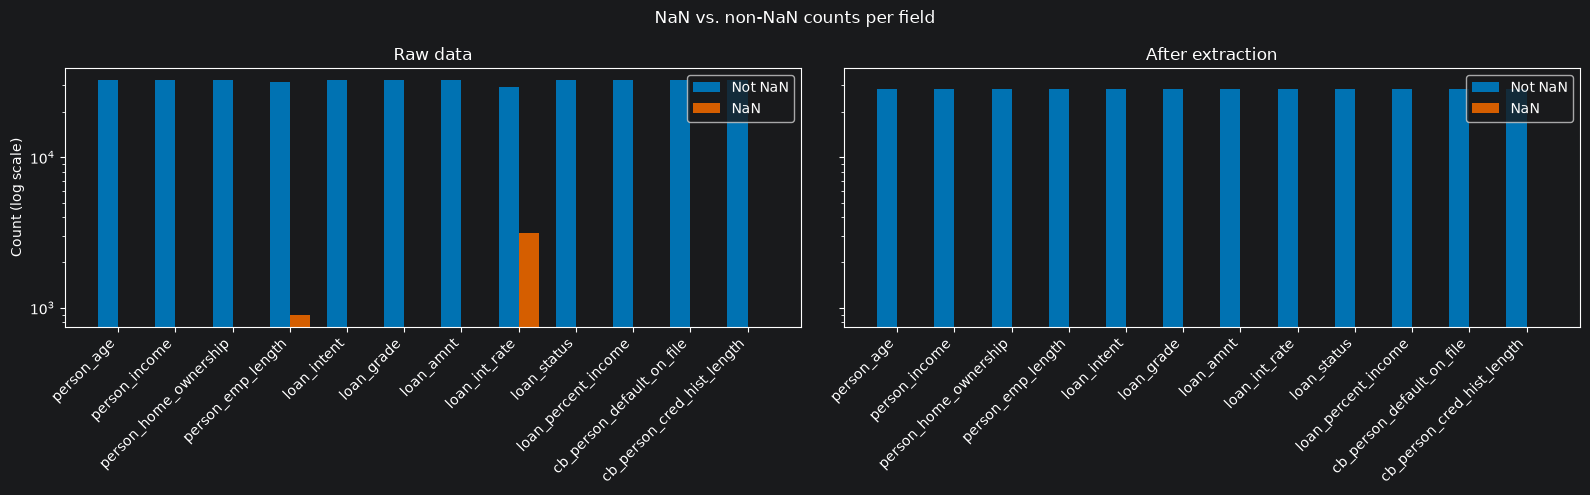

In [4]:
import matplotlib.pyplot as plt
from src.fetch import fetch_dataset

raw_df = fetch_dataset()
df = extract_data(raw_df)

# The whole point of extract_data is to leave no NaNs behind.
assert df.isna().sum().sum() == 0, "Extracted data still contains NaN values"

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
width = 0.35

for ax, data, title in [
    (axes[0], raw_df, "Raw data"),
    (axes[1], df, "After extraction"),
]:
    nan_counts = data.isna().sum()
    not_nan_counts = data.notna().sum()
    x = range(len(data.columns))

    ax.bar([i - width / 2 for i in x], not_nan_counts, width, label="Not NaN", color="#0072B2")
    ax.bar([i + width / 2 for i in x], nan_counts, width, label="NaN", color="#D55E00")

    ax.set_yscale("log")
    ax.set_xticks(list(x))
    ax.set_xticklabels(data.columns, rotation=45, ha="right")
    ax.set_title(title)
    ax.legend()

axes[0].set_ylabel("Count (log scale)")
fig.suptitle("NaN vs. non-NaN counts per field")

plt.tight_layout()
plt.show()